#Machine Learning em Ambientes Industriais.
##O que é Machine Learning?
São sistemas que aprendem automaticamente a partir de dados e experiências sem programação explícita de cada regra. Machine Learning é importante pois a partir dela é possível analisar volumes normes de dados que humanos não conseguiriam com tanta eficiência.<br>
O programação tradicional é como se fosse uma receita, são escritas todas as etapas que devem ser seguidas, passo a passo. No machine learning a própria máquina vai aprendendo com os dados, desde que estejam devidamente rotulados.
---

---
Importação das bibiliotecas necessárias para a atividade.
- Pandas será usado para a leitura dos arquivos .csv, filtragem e cálculo de alguns dados.
- O Matplotlib será usado para gerar os gráficos a respeito da análise dos dados.


In [9]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

Será atribuido na variável `arquivo` o arquivo desejado e na variável `df` será feita a leitura desse arquivo .csv dentro da função `pd.read_csv(insira nome da variável)`

In [2]:
arquivo = 'dados_aula1_machine_learning_industria.csv'
df = pd.read_csv(arquivo)

---
Exibindo algumas informações a respeito do dataset.

`.shape` vai exibir as informações sobre o dataframe em linhas e colunas
> Por exemplo, esse dataset tem 188 linhas e 15 colunas.

In [3]:
print("Dimensão: ", df.shape)

Dimensão:  (188, 15)


O `df.head()` vai exibir as 5 primeiras linhas do dataset.

In [4]:
df.head()

,timestamp,lote_producao,operador,modo_controle,status_valvula,setpoint_vazao_l_min,vazao_medida_l_min,pressao_linha_bar,temperatura_processo_c,abertura_valvula_pct,vibracao_bomba_mm_s,tempo_resposta_ms,ph_produto,densidade_produto_g_cm3,status_instrumentacao
0,2026-01-10 08:00:00,Lote_A,op_b,automatico,normal,121.44,128.08,3.518,95.00,56.97,2.960,220.8,7.09,1.069,estavel
1,2026-01-10 09:00:00,Lote_D,op_c,cascata,normal,126.17,119.32,4.616,43.34,63.26,2.532,402.1,6.99,1.053,inspecao
2,2026-01-10 10:00:00,Lote_B,op_d,manual,intermitente,128.54,129.11,4.118,40.67,63.14,2.182,284.1,6.72,1.021,inspecao
3,2026-01-10 11:00:00,Lote_C,op_a,automatico,intermitente,106.50,102.68,3.547,43.94,64.75,2.772,486.3,6.67,1.093,inspecao
4,2026-01-10 12:00:00,Lote_C,op_a,automatico,normal,101.59,NaN,4.085,102.00,83.82,3.173,283.3,6.66,1.004,estavel


O `.info()` vai exibir os tipos de dados presentes no dataframe, desde os tipos de variáveis, quantas células estão preenchidas e até mesmo a quantidade de memória que o dataframe consome.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 188 entries, 0 to 187
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   timestamp                188 non-null    object 
 1   lote_producao            188 non-null    object 
 2   operador                 183 non-null    object 
 3   modo_controle            183 non-null    object 
 4   status_valvula           188 non-null    object 
 5   setpoint_vazao_l_min     188 non-null    float64
 6   vazao_medida_l_min       176 non-null    float64
 7   pressao_linha_bar        178 non-null    float64
 8   temperatura_processo_c   178 non-null    float64
 9   abertura_valvula_pct     188 non-null    float64
 10  vibracao_bomba_mm_s      188 non-null    float64
 11  tempo_resposta_ms        177 non-null    float64
 12  ph_produto               180 non-null    float64
 13  densidade_produto_g_cm3  188 non-null    float64
 14  status_instrumentacao    1

O `.describe().T` vai exibir algumas estatísticas do dataframe, são elas:
- Quantidade de informações por categoria
- A média de cada categoria
- O valor mínimo e máximo de cada categoria
- Os valores que ficam entre o mínimo e o máximo nos 25%, 50% e 75%

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
setpoint_vazao_l_min,188.0,119.056277,12.164116,90.340,110.3375,119.2300,126.9200,156.950
vazao_medida_l_min,176.0,119.571761,13.808622,90.230,110.2875,118.5650,128.7800,160.330
pressao_linha_bar,178.0,3.954781,0.842332,2.811,3.5655,3.8865,4.1190,10.200
temperatura_processo_c,178.0,43.874213,9.399248,26.070,40.0275,43.1750,46.6650,110.000
abertura_valvula_pct,188.0,58.468617,16.380992,18.010,46.7575,58.6000,67.7500,99.280
vibracao_bomba_mm_s,188.0,2.336059,0.958364,0.386,1.7935,2.2900,2.7210,9.100
tempo_resposta_ms,177.0,337.286441,129.197193,130.100,278.2000,321.4000,377.5000,1500.000
ph_produto,180.0,6.806500,0.312416,6.040,6.6100,6.8200,7.0125,7.560
densidade_produto_g_cm3,188.0,1.040255,0.030946,0.949,1.0210,1.0395,1.0620,1.134


- `.isna()` vai fazer uma varredura no dataframe inteiro, verificando quais células estão como NaN, ele sozinho vai exibir um pedaço da tabela e se a célula estiver como NaN, vai estar como `True`
- O `astype(int)` vai substituir o `True` e `False` por 0 e 1.
- O `sum()` vai somar todos os valores `NaN`
- O `sort_values(ascending = False)` vai organizar todas as categorias em ordem descrescente, ou seja, da categoria que mais tem dados NaN para que tem menos dados NaN.

In [14]:
df.isna().astype(int).sum().sort_values(ascending = False)

,0
vazao_medida_l_min,12
tempo_resposta_ms,11
pressao_linha_bar,10
temperatura_processo_c,10
ph_produto,8
modo_controle,5
operador,5
setpoint_vazao_l_min,0
status_valvula,0
timestamp,0


Fazendo a leitura de algumas colunas em específico. Para isso, chamamos o dataframe, entre colchetes, fazemos uma lista das colunas que queremos exibir.
> Por exemplo, `df[['coluna1', 'coluna2']]`

In [21]:
df[['tempo_resposta_ms', 'operador']]

,tempo_resposta_ms,operador
0,220.8,op_b
1,402.1,op_c
2,284.1,op_d
3,486.3,op_a
4,283.3,op_a
...,...,...
183,265.0,op_b
184,308.3,op_b
185,226.5,op_c
186,250.3,op_b


Verificando se há duplicatas

Criando uma lista que armazene as colunas do dataframe que usam dados numéricos.

In [19]:
colunas_numericas = [
'setpoint_vazao_l_min',
'vazao_medida_l_min',
'pressao_linha_bar',
'temperatura_processo_c',
'abertura_valvula_pct',
'vibracao_bomba_mm_s',
'tempo_resposta_ms',
'ph_produto',
'densidade_produto_g_cm3'
]

Gerando os gráficos de cada uma dessas colunas numéricas através de um laço de repetição `for`.<br>
Dentro desse `for` são executados alguns comandos, sendo eles:
- `.figure(figsize = (8, 3))`, será gerado uma imagem e essa imagem terá as dimensões de 8 x 3.
- `.boxplot(df[coluna].dropna(), vert = False)` especifica o tipo de gráfico que será gerado, nesse caso, um Boxplot. Dentro da função temos algumas especificações, dentre elas:
  - `df[coluna]` indica qual a coluna que será usada como base pro gráfico
  - `.dropna()` após a indicação da coluna vai fazer a remoção de valores nulos
  - `vert = False` pede que o gráfico não seja no sentido vertical, ou seja, será gerado na horizontal
- `.title()` é o título que cada gráfico terá
- `.xlabel()` é o texto que o eixo X do gráfico vai receber
- `.show()` exibe o gráfico gerado
> Os itens que apresentam bolinhas significam que são valores que estão foram do padrão esperado (outliers).


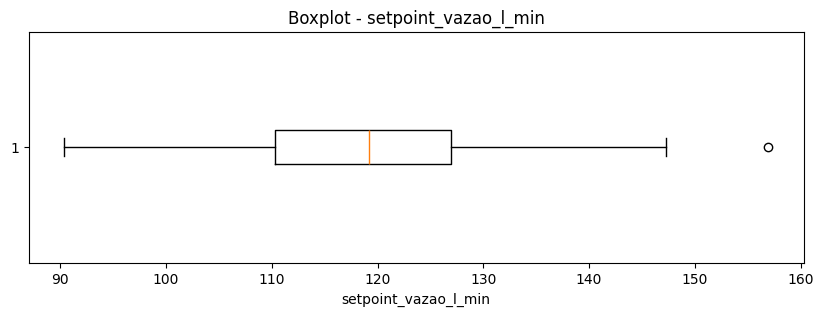

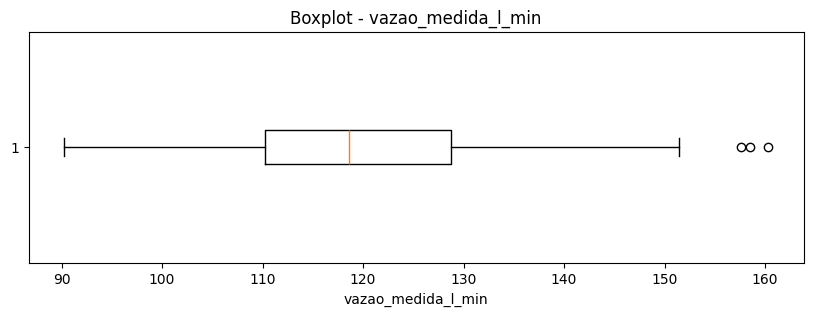

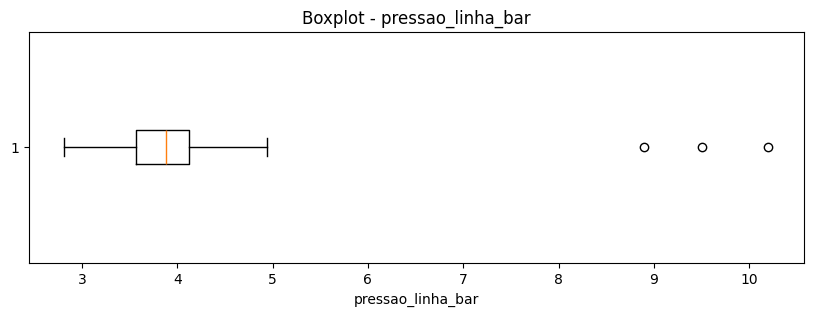

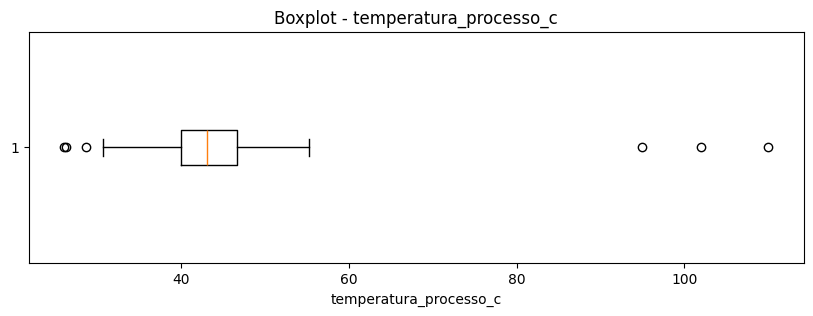

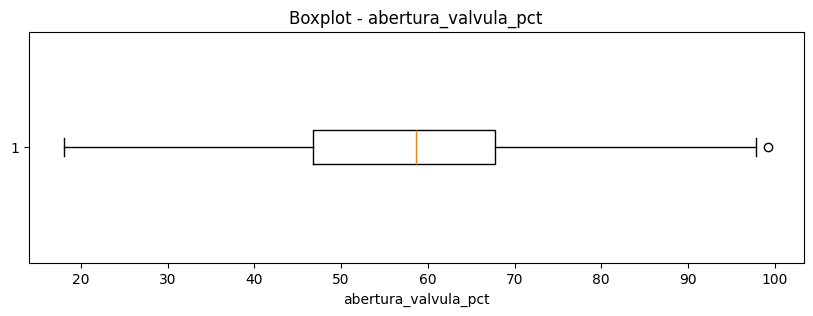

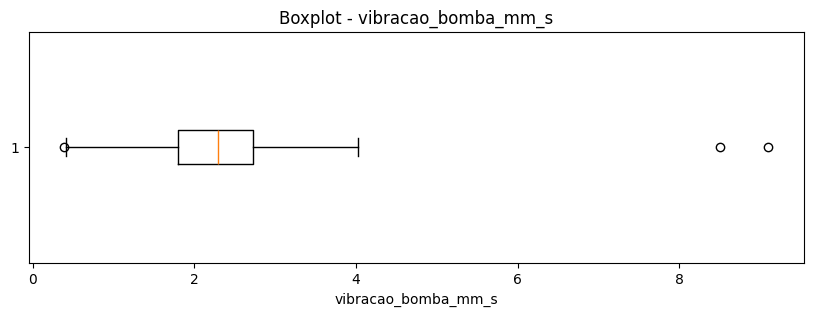

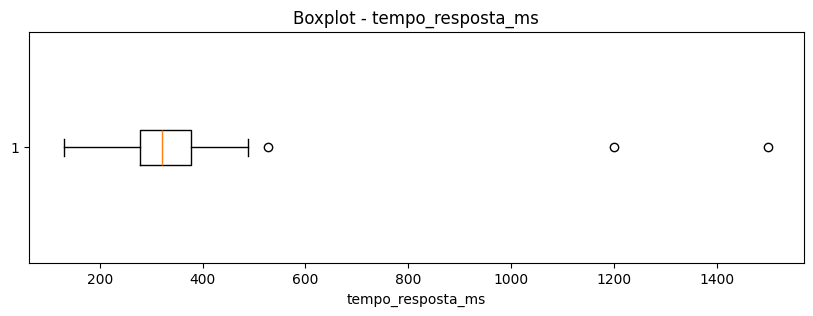

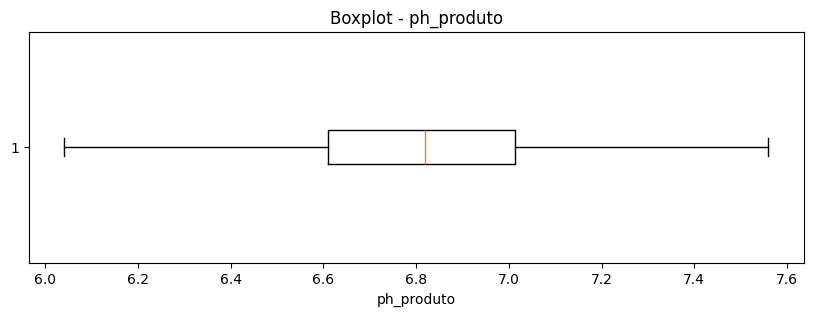

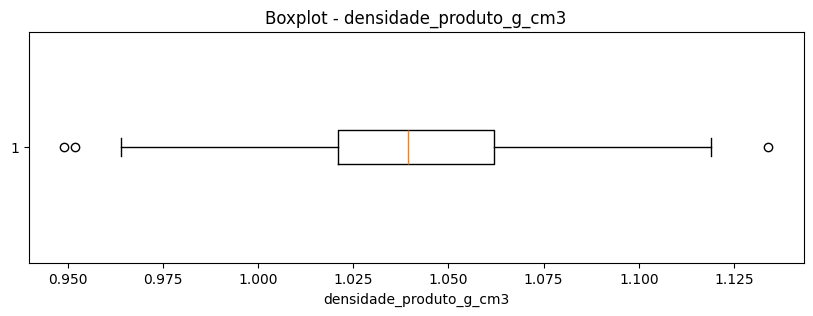

In [22]:
for coluna in colunas_numericas:
  plt.figure(figsize=(8, 3))
  plt.boxplot(df[coluna].dropna(), vert=False) # horizontal para melhor leitura
  plt.title(f'Boxplot - {coluna}')
  plt.xlabel(coluna)
  plt.show()

Exercício de exemplo para ver algumas colunas que apresentam outliers.

In [23]:
ex_outliers = ['pressao_linha_bar', 'temperatura_processo_c', 'vibracao_bomba_mm_s', 'tempo_resposta_ms']

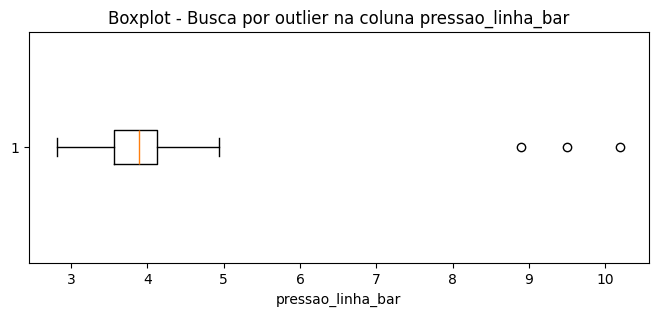

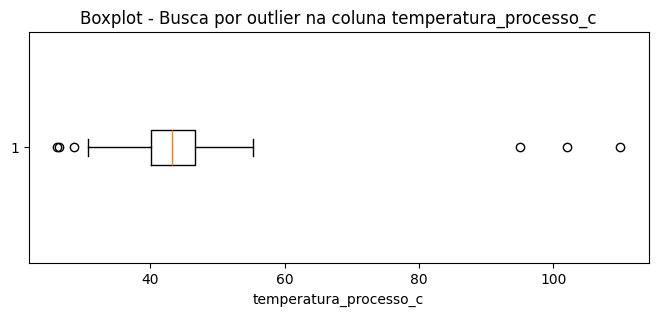

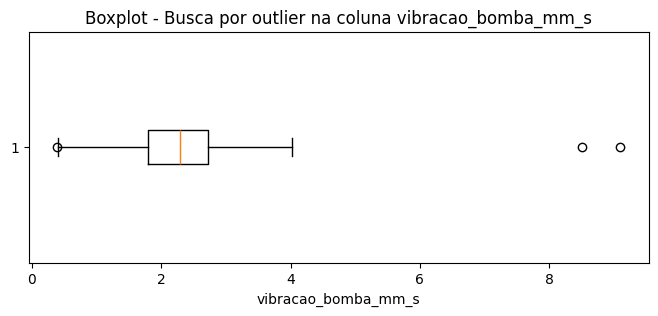

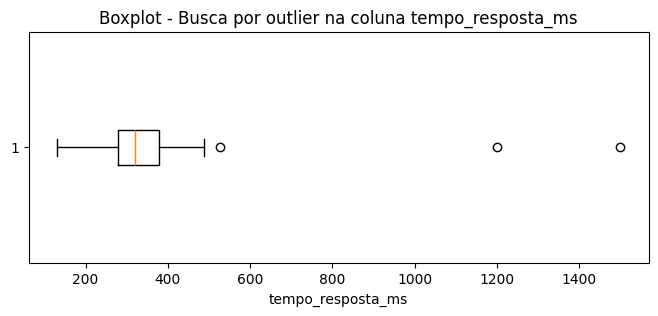

In [24]:
for outlier in ex_outliers:
  plt.figure(figsize = (8, 3))
  plt.boxplot(df[outlier].dropna(), vert = False)
  plt.title(f"Boxplot - Busca por outlier na coluna {outlier}")
  plt.xlabel(outlier)
  plt.show()

Gerando uma matriz de correlação numérica, para isso, dentro de um colchetes, inserimos as colunas (ou uma lista que tenha elas) e por fim chamamos a função `.corr()`
> Exemplo: `df[lista_de_colunas].corr()`

In [25]:
df[ex_outliers].corr()

,pressao_linha_bar,temperatura_processo_c,vibracao_bomba_mm_s,tempo_resposta_ms
pressao_linha_bar,1.000000,-0.040471,-0.004311,-0.034882
temperatura_processo_c,-0.040471,1.000000,0.057550,-0.016420
vibracao_bomba_mm_s,-0.004311,0.057550,1.000000,-0.064778
tempo_resposta_ms,-0.034882,-0.016420,-0.064778,1.000000


Criando a variável auxiliar `desvio_vazao_abs`, ela usará como base as colunas `setpoint_vazao_l_min` e `vazao_medida_l_min` e, após feito esse cálculo, é gerado o valor absoluto (valores positivos) com a função `.abs()`

In [28]:
df['desvio_vazao_abs'] = (df['setpoint_vazao_l_min'] - df['vazao_medida_l_min']).abs()

In [29]:
df['desvio_vazao_abs'].describe()

,desvio_vazao_abs
count,176.000000
mean,6.539773
std,5.079625
min,0.110000
25%,2.405000
50%,5.660000
75%,9.825000
max,21.580000


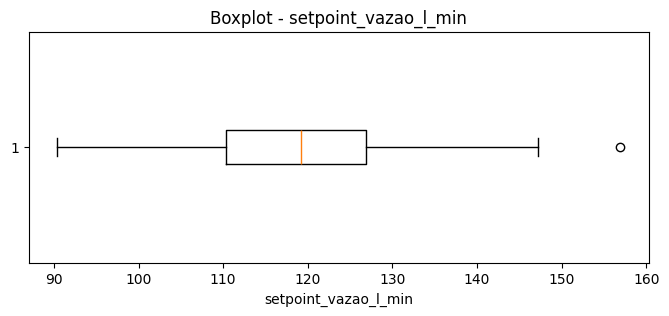

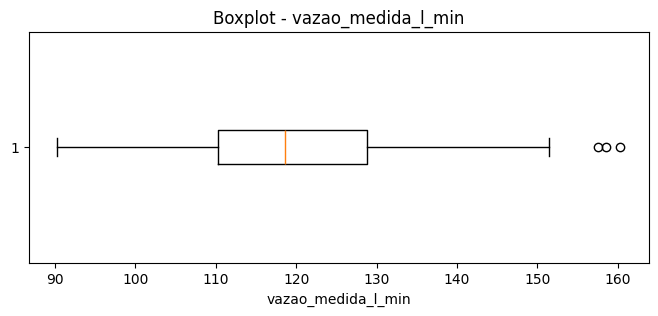

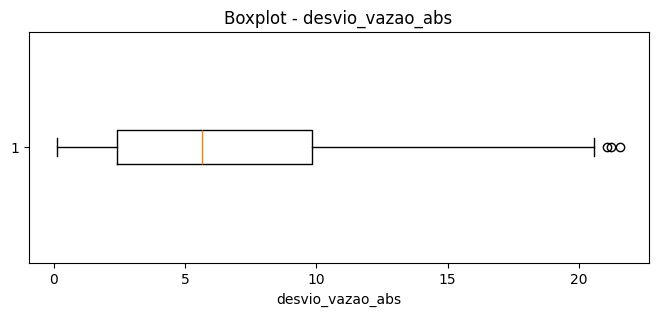

In [31]:
colunas_vazao = [
'setpoint_vazao_l_min',
'vazao_medida_l_min',
'desvio_vazao_abs'
]

for coluna in colunas_vazao:
  plt.figure(figsize=(8, 3))
  plt.boxplot(df[coluna].dropna(), vert=False) # horizontal para melhor leitura
  plt.title(f'Boxplot - {coluna}')
  plt.xlabel(coluna)
  plt.show()